# 03 · Feature Engineering
Turning cleaned resume fields into numbers that describe **(a)** the candidate and **(b)** how well the
candidate fits a specific job description.

### Why job descriptions had to be created
The dataset has candidates but **no job descriptions and no "hired / shortlisted" column**. To match candidates to roles,
10 realistic job descriptions were written (`data/job_descriptions.csv`) covering every domain in the data. Each JD lists:
*mandatory skills, optional skills, preferred tools, experience range, seniority, required experience areas (flags),
preferred education fields* and a free-text description.

In [1]:
# --- Setup -----------------------------------------------------------
# Add the project root folder to the Python path so "src" can be imported
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

# Standard libraries for data handling and charts
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")          # hide library warnings so the output stays readable
pd.set_option("display.max_columns", 60)   # show all columns when printing a dataframe
pd.set_option("display.max_colwidth", 80)  # do not cut long text too early

# Project settings: file paths, colours and the chart style
from src.config import *
from src.plot_style import set_style, save
set_style()

In [2]:
from src.cleaning import load_cleaned
from src.features import build_candidate_features, build_pair_features, to_list
from src.matching import fit_text_models, text_similarity

# cleaned candidates from notebook 01 and the job descriptions
df = load_cleaned(CLEANED_FILE)
jds = pd.read_csv(JD_FILE)
jds[["jd_id", "job_title", "target_domain", "mandatory_skills", "optional_skills", "min_years", "max_years", "seniority"]]

,jd_id,job_title,target_domain,mandatory_skills,optional_skills,min_years,max_years,seniority
0,JD01,Senior Cloud Backend Engineer,IT,Python|AWS|Docker,Kubernetes|Linux|Git,6,15,Senior
1,JD02,DevOps Engineer,IT,Docker|Kubernetes|Linux,Git|AWS|Python,3,8,Mid
2,JD03,Junior Java Developer,IT,Java|Git,SQL|Linux|Docker,1,4,Junior
3,JD04,Data Scientist - NLP,Data Science,Python|Machine Learning|NLP,TensorFlow|Pandas|SQL,3,8,Mid
4,JD05,Business Data Analyst,Data Science,SQL|Power BI,Python|Pandas,2,6,Mid
5,JD06,HR Business Partner,HR,HR Analytics|Employee Engagement,HRMS|Payroll|Recruitment,5,12,Senior
6,JD07,Talent Acquisition Specialist,HR,Recruitment|HRMS,HR Analytics|Employee Engagement,2,7,Mid
7,JD08,Corporate Compliance Counsel,Legal,Contract Drafting|Compliance,Due Diligence|Legal Research,4,10,Mid
8,JD09,Mechanical Design Engineer,Engineering,CAD|SolidWorks,Manufacturing|Quality Control,2,8,Mid
9,JD10,Senior IT Project Manager,Management,Agile|Stakeholder Management|Risk Management,Strategy,8,20,Senior


## Part A — Candidate features

In [3]:
# Build all candidate-level features in one call (logic lives in src/features.py)
cand = build_candidate_features(df)

new_cols = ["n_skills", "n_tools", "cloud_tool_count", "main_skill_family", "skill_domain_alignment",
            "experience_bucket", "seniority_level", "education_rank", "leadership_score", "delivery_score",
            "client_score", "governance_score", "achievement_pct", "project_lead_flag",
            "keyword_stuffing_flag", "resume_quality_score"]
cand[["candidate_id", "primary_role"] + new_cols].head()

,candidate_id,primary_role,n_skills,n_tools,cloud_tool_count,main_skill_family,skill_domain_alignment,experience_bucket,seniority_level,education_rank,leadership_score,delivery_score,client_score,governance_score,achievement_pct,project_lead_flag,keyword_stuffing_flag,resume_quality_score
0,CND_100001,Data Analyst,4,2,1,Data & ML,1.0,Senior (6-10),Mid,2,0.25,0.8,1.0,0.333,9.0,0,0,0.673
1,CND_100002,Senior Software Engineer,4,2,1,Software & Cloud,1.0,Senior (6-10),Senior,2,1.00,1.0,1.0,0.667,43.0,1,1,0.614
2,CND_100003,Compliance Officer,4,2,1,Legal,1.0,Senior (6-10),Mid,2,0.25,0.6,1.0,1.000,23.0,0,0,0.656
3,CND_100004,Senior Software Engineer,4,2,2,Software & Cloud,1.0,Senior (6-10),Senior,2,0.75,1.0,1.0,0.667,42.0,0,0,0.827
4,CND_100005,Software Engineer,4,2,1,Software & Cloud,1.0,Senior (6-10),Mid,2,0.75,1.0,1.0,0.667,15.0,0,0,0.594


In [4]:
# Justification for every candidate feature
candidate_feature_doc = pd.DataFrame([
    ["skills_clean", "List of canonical skills after fuzzy correction", "Fair matching - typos no longer hide a skill"],
    ["main_skill_family / skill_domain_alignment", "Most common skill family; share of skills that belong to the candidate's domain", "Shows how focused a profile is (specialist vs scattered)"],
    ["experience_bucket", "Entry 0-2 / Mid 3-5 / Senior 6-10 / Expert 11+", "Easy grouping for recruiters and charts"],
    ["seniority_level", "Junior / Mid / Senior from the job title", "Compared against the seniority asked in the JD"],
    ["leadership_score", "Mean of management, people mgmt, mentoring, delivery-lead flags", "Readiness for lead roles in one number (flags overlap - see EDA H2)"],
    ["delivery_score", "Mean of PM, agile, delivery-lead, offshore-onsite, multi-vendor flags", "Delivery maturity for IT services roles"],
    ["client_score", "Mean of client-facing and stakeholder flags", "Fit for consulting / client roles"],
    ["governance_score", "Mean of compliance, process-compliance, documentation flags", "Fit for legal, audit, process-heavy roles"],
    ["achievement_pct", "% number pulled out of key_achievements with regex", "Simple measurable-impact signal"],
    ["project_lead_flag", "1 if project summary starts with 'Led'", "Ownership vs participation"],
    ["keyword_stuffing_flag", "keyword_density_score > 0.85", "Spot resumes that try to game the ATS"],
    ["resume_quality_score", "0.6 completeness + 0.2 length + 0.2 no-stuffing - 0.1 missing education", "Small tie-breaker for profile quality"],
    ["profile_text", "Role + domain + skills + tools + soft skills + summaries in one cleaned string", "Input for the NLP similarity models"],
], columns=["feature", "logic", "why it helps"])
candidate_feature_doc

,feature,logic,why it helps
0,skills_clean,List of canonical skills after fuzzy correction,Fair matching - typos no longer hide a skill
1,main_skill_family / skill_domain_alignment,Most common skill family; share of skills that belong to the candidate's domain,Shows how focused a profile is (specialist vs scattered)
2,experience_bucket,Entry 0-2 / Mid 3-5 / Senior 6-10 / Expert 11+,Easy grouping for recruiters and charts
3,seniority_level,Junior / Mid / Senior from the job title,Compared against the seniority asked in the JD
4,leadership_score,"Mean of management, people mgmt, mentoring, delivery-lead flags",Readiness for lead roles in one number (flags overlap - see EDA H2)
5,delivery_score,"Mean of PM, agile, delivery-lead, offshore-onsite, multi-vendor flags",Delivery maturity for IT services roles
6,client_score,Mean of client-facing and stakeholder flags,Fit for consulting / client roles
7,governance_score,"Mean of compliance, process-compliance, documentation flags","Fit for legal, audit, process-heavy roles"
8,achievement_pct,% number pulled out of key_achievements with regex,Simple measurable-impact signal
9,project_lead_flag,1 if project summary starts with 'Led',Ownership vs participation


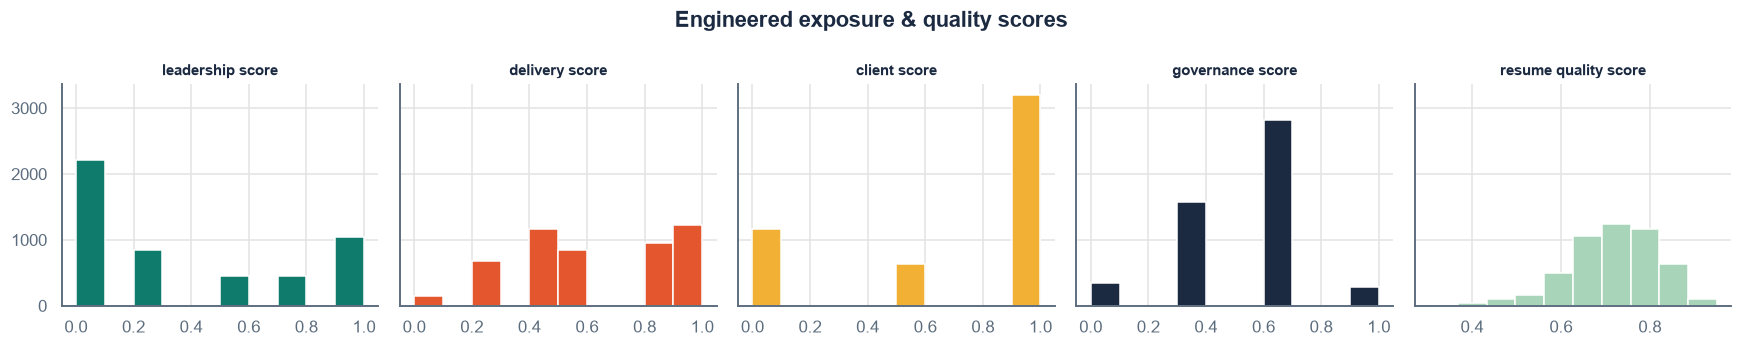

In [5]:
# Distribution of the exposure scores
score_cols = ["leadership_score", "delivery_score", "client_score", "governance_score", "resume_quality_score"]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2), sharey=True)
for ax, col, colr in zip(axes, score_cols, PALETTE):
    ax.hist(cand[col], bins=10, color=colr, edgecolor="white")
    ax.set_title(col.replace("_", " "), fontsize=10)
fig.suptitle("Engineered exposure & quality scores", fontweight="bold", color=COLORS["ink"])
fig.tight_layout()
save(fig, "03_exposure_scores")
plt.show()

## Part B — NLP text representations
Two text-similarity measures compare each candidate's `profile_text` with the JD text:
- **TF-IDF cosine** – overlap of important words / two-word phrases.
- **LSA cosine** – TF-IDF compressed into 50 "topics" with Truncated SVD, so related words
  (e.g. *docker* & *kubernetes*, *recruitment* & *hiring*) count as similar even when the exact word differs.

In [6]:
# Fit TF-IDF + LSA on all candidate texts and JD texts together
tfidf, lsa = fit_text_models(cand["profile_text"], jds["jd_text"], n_topics=50)
print("Vocabulary size:", len(tfidf.vocabulary_))
print("Variance kept by 50 LSA topics:", round(lsa.explained_variance_ratio_.sum(), 3))

# save the fitted text models so the dashboard can reuse them
import joblib
joblib.dump(tfidf, MODELS / "tfidf_vectorizer.pkl")
joblib.dump(lsa, MODELS / "lsa_svd.pkl")

Vocabulary size: 543
Variance kept by 50 LSA topics: 0.815


['models/lsa_svd.pkl']

In [7]:
# Example: the words that matter most in one profile
example = tfidf.transform([cand.loc[1, "profile_text"]])
terms = np.array(tfidf.get_feature_names_out())
top_idx = example.toarray().ravel().argsort()[::-1][:10]
print(cand.loc[1, "profile_text"][:200], "...")
pd.DataFrame({"term": terms[top_idx], "tfidf_weight": example.toarray().ravel()[top_idx].round(3)})

senior software engineer. it. skills: docker, git, kubernetes, python. tools: aws, jira. teamwork, communication. over years delivering solutions in it, collaborating with cross-functional teams and s ...


,term,tfidf_weight
0,jira teamwork,0.185
1,teamwork communication,0.183
2,aws jira,0.178
3,kubernetes python,0.167
4,git kubernetes,0.165
5,senior software,0.159
6,senior,0.155
7,goals led,0.153
8,performance contributed,0.151
9,docker git,0.149


## Part C — Candidate × Job pair features

In [8]:
# Score every candidate against every JD -> 5,000 x 10 = 50,000 rows
pair_list = []
for _, jd in jds.iterrows():
    p = build_pair_features(cand, jd)
    p["tfidf_sim"], p["lsa_sim"] = text_similarity(tfidf, lsa, cand["profile_text"], jd["jd_text"])
    pair_list.append(p)
pairs = pd.concat(pair_list, ignore_index=True)

# Raw cosine values are small and differ by JD, so they are min-max scaled within each JD (0 = worst, 1 = best)
for col in ["tfidf_sim", "lsa_sim"]:
    g = pairs.groupby("jd_id")[col]
    pairs[col + "_scaled"] = (pairs[col] - g.transform("min")) / (g.transform("max") - g.transform("min"))
pairs["text_sim_scaled"] = pairs[["tfidf_sim_scaled", "lsa_sim_scaled"]].mean(axis=1)

print(pairs.shape)
pairs.head()

(50000, 32)


,candidate_id,jd_id,mandatory_matched,mandatory_missing,optional_matched,mandatory_match,optional_match,all_mandatory_flag,tool_match,years_experience,years_gap,experience_fit,seniority_fit,domain_fit,role_fit,flag_fit,education_fit,resume_quality_score,leadership_score,delivery_score,client_score,governance_score,skill_domain_alignment,achievement_pct,project_lead_flag,education_rank,n_tools,tfidf_sim,lsa_sim,tfidf_sim_scaled,lsa_sim_scaled,text_sim_scaled
0,CND_100001,JD01,"[Python, AWS]",[Docker],[],0.666667,0.000000,0,0.5,7,0,1.0,0.5,0.5,0.0,0.333333,0.2,0.673,0.25,0.8,1.0,0.333,1.0,9.0,0,2,2,0.048341,0.288117,0.323916,0.402993,0.363455
1,CND_100002,JD01,"[Python, AWS, Docker]",[],"[Kubernetes, Git]",1.000000,0.666667,1,1.0,10,0,1.0,1.0,1.0,1.0,0.666667,1.0,0.614,1.00,1.0,1.0,0.667,1.0,43.0,1,2,2,0.060768,0.349482,0.418456,0.494081,0.456269
2,CND_100003,JD01,[AWS],"[Python, Docker]",[],0.333333,0.000000,0,0.5,7,0,1.0,0.5,0.0,0.0,0.000000,0.2,0.656,0.25,0.6,1.0,1.000,1.0,23.0,0,2,2,0.040707,0.231059,0.265835,0.318296,0.292066
3,CND_100004,JD01,"[AWS, Docker]",[Python],[Kubernetes],0.666667,0.333333,0,0.0,9,0,1.0,1.0,1.0,1.0,1.000000,1.0,0.827,0.75,1.0,1.0,0.667,1.0,42.0,0,2,2,0.117830,0.546494,0.852582,0.786523,0.819553
4,CND_100005,JD01,[AWS],"[Python, Docker]","[Kubernetes, Git]",0.333333,0.666667,0,0.5,9,0,1.0,0.5,1.0,1.0,1.000000,1.0,0.594,0.75,1.0,1.0,0.667,1.0,15.0,0,2,2,0.068276,0.420182,0.475579,0.599028,0.537303


In [9]:
# Justification for every candidate x job (pair) feature
pair_feature_doc = pd.DataFrame([
    ["mandatory_match", "Share of JD must-have skills found in skills + tools", "Most important hiring filter"],
    ["optional_match", "Share of nice-to-have skills found", "Separates good from great candidates"],
    ["all_mandatory_flag", "1 if every must-have skill is present", "Simple knock-out indicator for recruiters"],
    ["tool_match", "Share of preferred tools/platforms found", "Ramp-up time on the client's stack"],
    ["experience_fit", "1 inside JD range; -0.25/yr below min; -0.05/yr above max (floor 0.6)", "Under-experience is riskier than over-experience"],
    ["years_gap", "Years outside the JD range (negative = below)", "Explainability"],
    ["seniority_fit", "1 same level, 0.5 one level apart, 0 otherwise", "Checks title level, not just years"],
    ["domain_fit", "1 same domain, 0.5 related domain, 0 otherwise", "Functional background alignment"],
    ["role_fit", "1 if role is in JD target roles, 0.4 same domain, 0 otherwise", "Stated designation alignment"],
    ["flag_fit", "Share of JD-required experience areas the candidate has", "e.g. cloud, agile, people management"],
    ["education_fit", "1 preferred field, 0.2 other field, 0.5 not specified", "Missing data is not punished"],
    ["tfidf_sim / lsa_sim (+ scaled)", "Cosine similarity of profile text vs JD text", "NLP signal beyond exact keywords"],
], columns=["feature", "logic", "why it helps"])
pair_feature_doc

,feature,logic,why it helps
0,mandatory_match,Share of JD must-have skills found in skills + tools,Most important hiring filter
1,optional_match,Share of nice-to-have skills found,Separates good from great candidates
2,all_mandatory_flag,1 if every must-have skill is present,Simple knock-out indicator for recruiters
3,tool_match,Share of preferred tools/platforms found,Ramp-up time on the client's stack
4,experience_fit,1 inside JD range; -0.25/yr below min; -0.05/yr above max (floor 0.6),Under-experience is riskier than over-experience
5,years_gap,Years outside the JD range (negative = below),Explainability
6,seniority_fit,"1 same level, 0.5 one level apart, 0 otherwise","Checks title level, not just years"
7,domain_fit,"1 same domain, 0.5 related domain, 0 otherwise",Functional background alignment
8,role_fit,"1 if role is in JD target roles, 0.4 same domain, 0 otherwise",Stated designation alignment
9,flag_fit,Share of JD-required experience areas the candidate has,"e.g. cloud, agile, people management"


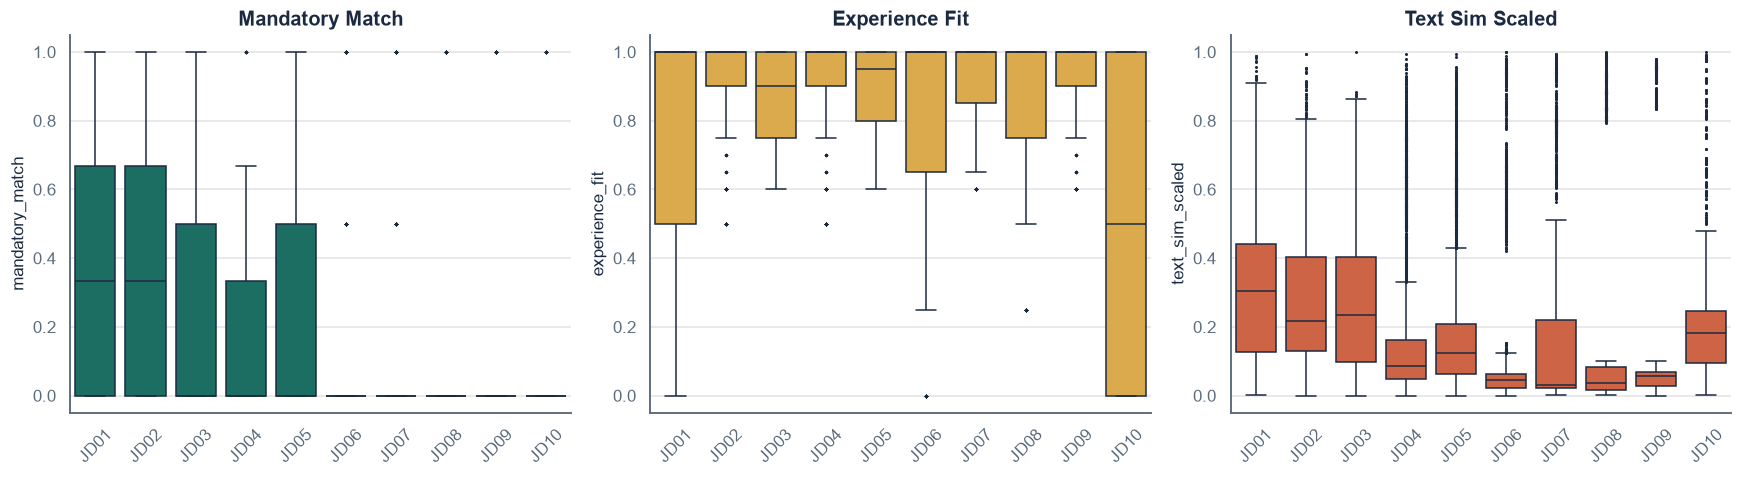

In [10]:
# How do the key match features look for each job?
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, colr in zip(axes, ["mandatory_match", "experience_fit", "text_sim_scaled"],
                         [COLORS["teal"], COLORS["mustard"], COLORS["coral"]]):
    sns.boxplot(data=pairs, x="jd_id", y=col, ax=ax, color=colr, linecolor=COLORS["ink"], fliersize=1)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
save(fig, "03_pair_features_by_jd")
plt.show()

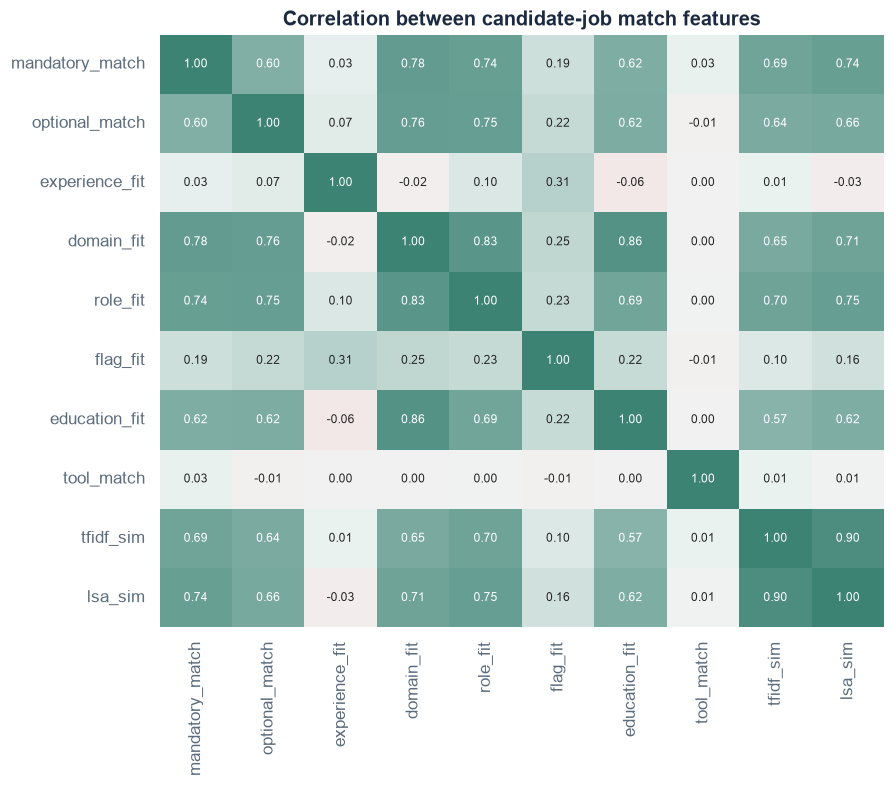

In [11]:
# Does text similarity agree with skill matching? (correlation of pair features)
corr_cols = ["mandatory_match", "optional_match", "experience_fit", "domain_fit", "role_fit",
             "flag_fit", "education_fit", "tool_match", "tfidf_sim", "lsa_sim"]
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(pairs[corr_cols].corr(), annot=True, fmt=".2f", cmap=sns.diverging_palette(15, 170, as_cmap=True),
            center=0, ax=ax, cbar=False, annot_kws={"size": 8})
ax.set_title("Correlation between candidate-job match features")
save(fig, "03_pair_feature_corr")
plt.show()

**Reading the correlations:** domain and role fit are strongly related (as expected); LSA similarity correlates
slightly more with skill/domain fit than plain TF-IDF, showing the topic model picks up meaning beyond exact words.
Mandatory-skill match is only partly explained by text similarity, so both are worth keeping.

In [12]:
# Save candidate features and pair features for the modelling notebook
cand_save = cand.copy()
for c in ["skills_clean", "tools_clean", "soft_skills_clean"]:
    cand_save[c] = cand_save[c].apply("|".join)
cand_save.to_csv(CANDIDATE_FEATURES_FILE, index=False)

pairs_save = pairs.copy()
for c in ["mandatory_matched", "mandatory_missing", "optional_matched"]:
    pairs_save[c] = pairs_save[c].apply("|".join)
pairs_save.to_csv(PAIR_FEATURES_FILE, index=False)

pd.concat([candidate_feature_doc.assign(level="candidate"), pair_feature_doc.assign(level="candidate x job")]) \
  .to_csv(OUTPUTS / "feature_dictionary.csv", index=False)
print("Saved", CANDIDATE_FEATURES_FILE.name, cand_save.shape, "and", PAIR_FEATURES_FILE.name, pairs_save.shape)

Saved candidate_features.csv (5000, 60) and candidate_jd_pairs.csv (50000, 32)
